[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DaTrollMon/schutz-gr-solutions-3rd/blob/main/Ch.1/Problem_1.11.ipynb)

# Chapter 1, Problem 11 — the invariant hyperbolae share the light cone as asymptotes

**Problem (paraphrased).** Show that the hyperbolae $-t^2 + x^2 = a^2$ and $-t^2 + x^2 = -b^2$ are asymptotic to the lines $t = \pm x$, regardless of $a$ and $b$.

**What "asymptotic" means.** A curve is asymptotic to a line if the distance between them goes to zero as we move to infinity along the curve. In the $t$–$x$ plane, for the line $t = x$, it's enough to show that $t - x \to 0$ along the relevant branch as $|t|, |x| \to \infty$ (and likewise $t + x \to 0$ for $t = -x$). The perpendicular distance from $(t,x)$ to $t = x$ is $|t - x|/\sqrt2$.

In [1]:
# --- setup: shared code for Colab / Codespaces ---
# Locally (uv sync) this does nothing. On Colab it installs the shared `schutz_gr`
# package from GitHub the first time the notebook runs.
try:
    import schutz_gr
except ImportError:
    %pip install -q "git+https://github.com/DaTrollMon/schutz-gr-solutions-3rd"
    import schutz_gr

## Method 1 — factor the difference of squares

Write both hyperbolae as $x^2 - t^2 = k$, with $k = a^2 > 0$ (spacelike hyperbola) or $k = -b^2 < 0$ (timelike hyperbola). Factor:
$$
(x - t)(x + t) = k .
$$

**Along the branches heading toward $t = x$**, i.e. going to infinity with $x$ and $t$ both large and of the same sign (so $|x + t| \to \infty$):
$$
x - t = \frac{k}{x + t} \longrightarrow 0 .
$$
So the curve approaches the line $t = x$.

**Along the branches heading toward $t = -x$** ($x$ and $t$ large with opposite signs, $|x - t| \to \infty$):
$$
x + t = \frac{k}{x - t} \longrightarrow 0 ,
$$
so the curve approaches $t = -x$.

The value of $k$ only sets the *rate* of approach ($\propto |k|/|x\pm t|$), never the limit. So the result holds for any $a$ and $b$ — and indeed for any $k$, with $k = 0$ being the light cone itself.

## Method 2 — explicit functions and slopes

**Spacelike hyperbola** $x^2 - t^2 = a^2$: the right branch is $x = \sqrt{t^2 + a^2}$. As $t\to+\infty$,
$$
x - t = \sqrt{t^2+a^2} - t = \frac{a^2}{\sqrt{t^2+a^2}+t} \approx \frac{a^2}{2t} \to 0^+ ,
$$
so $x$ approaches $t$ from the right, i.e. from outside the light cone. The slope also matches: $dx/dt = t/\sqrt{t^2+a^2} \to 1$.

**Timelike hyperbola** $t^2 - x^2 = b^2$: the upper branch is $t = \sqrt{x^2 + b^2}$. As $x\to+\infty$,
$$
t - x = \frac{b^2}{\sqrt{x^2+b^2}+x} \approx \frac{b^2}{2x} \to 0^+ ,
$$
approaching from inside the light cone (above the line $t = x$), with $dt/dx = x/\sqrt{x^2+b^2} \to 1$.

The other branches and the $t = -x$ asymptote follow from the symmetries $x \to -x$ and $t \to -t$, which leave both equations unchanged.

In [2]:
import sympy as sp
t, x = sp.symbols("t x", real=True)
a, b = sp.symbols("a b", positive=True)

xs = sp.sqrt(t**2 + a**2)          # spacelike hyperbola, right branch
tt = sp.sqrt(x**2 + b**2)          # timelike hyperbola, upper branch
print("spacelike:  lim (x − t) as t→∞  =", sp.limit(xs - t, t, sp.oo),
      ",  lim dx/dt =", sp.limit(sp.diff(xs, t), t, sp.oo))
print("timelike:   lim (t − x) as x→∞  =", sp.limit(tt - x, x, sp.oo),
      ",  lim dt/dx =", sp.limit(sp.diff(tt, x), x, sp.oo))
print("leading behaviour:", sp.series(xs - t, t, sp.oo, 3).removeO(), " | ", sp.series(tt - x, x, sp.oo, 3).removeO())

spacelike:  lim (x − t) as t→∞  = 0 ,  lim dx/dt = 1
timelike:   lim (t − x) as x→∞  = 0 ,  lim dt/dx = 1


leading behaviour: a**2/(2*t)  |  b**2/(2*x)


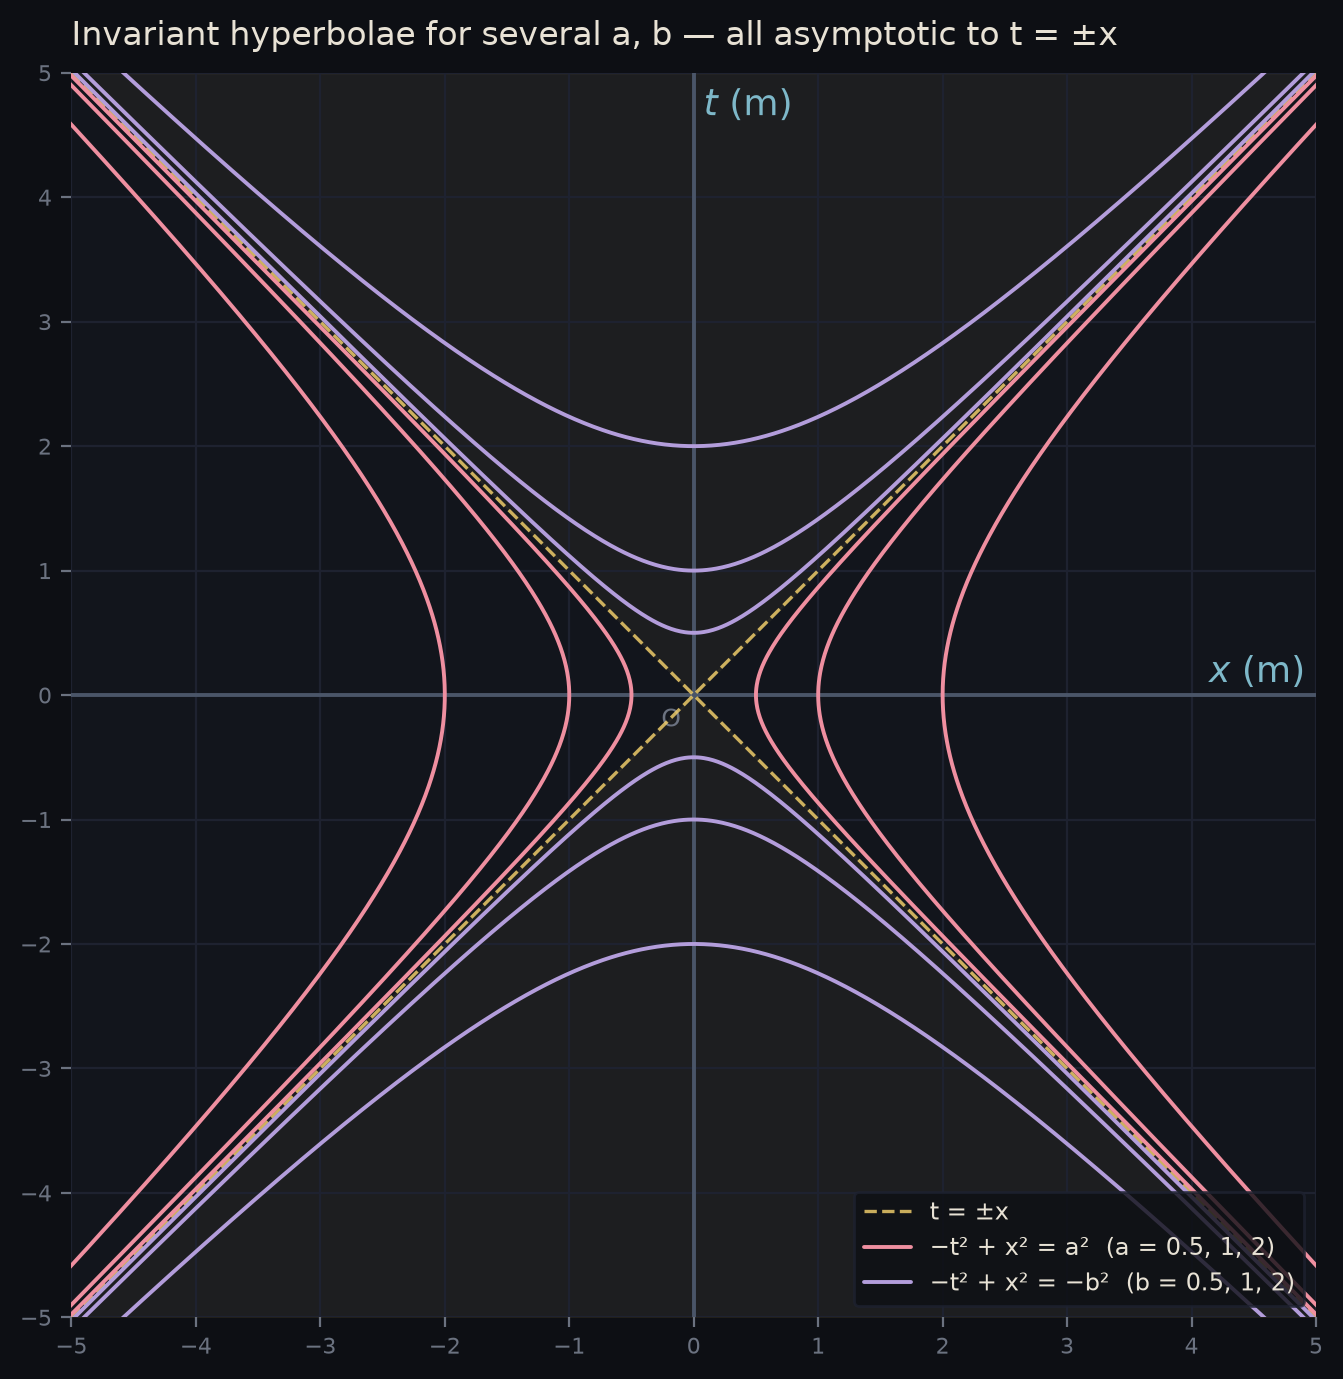

In [3]:
import numpy as np
from schutz_gr.diagrams import SpacetimeDiagram, COLORS
%config InlineBackend.figure_format = 'retina'

d = SpacetimeDiagram(xlim=(-5, 5), tlim=(-5, 5), title="Invariant hyperbolae for several a, b — all asymptotic to t = ±x", size=7)
d.light_cone(label="t = ±x", color="gold")
for k, (a_, c) in enumerate(((0.5, "rose"), (1, "rose"), (2, "rose"))):
    d.hyperbola(+a_**2, color=c, lw=1.4, label="−t² + x² = a²  (a = 0.5, 1, 2)" if k == 0 else None)
for k, b_ in enumerate((0.5, 1, 2)):
    d.hyperbola(-b_**2, color="violet", lw=1.4, label="−t² + x² = −b²  (b = 0.5, 1, 2)" if k == 0 else None)
d.show(loc="lower right")

In [4]:
# how fast the gap closes: perpendicular distance |x − t|/√2 from the line t = x
for a_ in (0.5, 1, 2):
    T = np.array([1, 10, 100, 1000.0])
    gap = (np.sqrt(T**2 + a_**2) - T) / np.sqrt(2)
    print(f"a = {a_}:  distance to t = x at t = 1, 10, 100, 1000 →", np.array2string(gap, precision=6))

a = 0.5:  distance to t = x at t = 1, 10, 100, 1000 → [8.346263e-02 8.833317e-03 8.838780e-04 8.838834e-05]
a = 1:  distance to t = x at t = 1, 10, 100, 1000 → [0.292893 0.035267 0.003535 0.000354]
a = 2:  distance to t = x at t = 1, 10, 100, 1000 → [0.874032 0.140035 0.014141 0.001414]


## Why it matters

All the invariant hyperbolae $\Delta s^2 = \text{const}$ share the light cone as their common asymptote. Physically: a sequence of events at fixed proper time (or proper distance) from the origin, viewed from frames moving faster and faster, gets pushed toward the light cone but never crosses it. The light cone is the $\Delta s^2 = 0$ member of the family, and it's the same for every observer. That's why it serves as the "frame" against which the calibration of every observer's axes is drawn (§1.7).